In [18]:
import pandas as pd
import numpy as np

df = pd.read_csv("iris.csv")
df.head()

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [19]:
df.isna().sum()

sepal.length    0
sepal.width     0
petal.length    0
petal.width     0
variety         0
dtype: int64

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

In [21]:
result_mapping = {
    "Setosa": 0,
    "Versicolor": 1,
    "Virginica": 2,
}

df["variety"] = df["variety"].map(result_mapping)

In [22]:
X = df.drop("variety", axis=1)
y = df["variety"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=15
)

In [23]:
def evaluate_knn(k):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    y_pred_test = knn.predict(X_test)
    y_pred_train = knn.predict(X_train)

    print(f"\n========== K = {k} ==========")

    print("\nTest Statistics")
    print(confusion_matrix(y_test, y_pred_test))
    print(accuracy_score(y_test, y_pred_test))
    print(precision_score(y_test, y_pred_test, average='micro'))
    print(recall_score(y_test, y_pred_test, average='micro'))

    print("\nTrain Statistics")
    print(confusion_matrix(y_train, y_pred_train))
    print(accuracy_score(y_train, y_pred_train))
    print(precision_score(y_train, y_pred_train, average='micro'))
    print(recall_score(y_train, y_pred_train, average='micro'))

    return knn

In [24]:
knn3 = evaluate_knn(3)


========== K = 3 ==========

Test Statistics
[[ 8  0  0]
 [ 0 13  0]
 [ 0  0  9]]
1.0
1.0
1.0

Train Statistics
[[42  0  0]
 [ 0 34  3]
 [ 0  3 38]]
0.95
0.95
0.95


In [25]:
knn5 = evaluate_knn(5)


========== K = 5 ==========

Test Statistics
[[ 8  0  0]
 [ 0 13  0]
 [ 0  0  9]]
1.0
1.0
1.0

Train Statistics
[[42  0  0]
 [ 0 34  3]
 [ 0  2 39]]
0.9583333333333334
0.9583333333333334
0.9583333333333334


In [26]:
knn7 = evaluate_knn(7)


========== K = 7 ==========

Test Statistics
[[ 8  0  0]
 [ 0 13  0]
 [ 0  0  9]]
1.0
1.0
1.0

Train Statistics
[[42  0  0]
 [ 0 34  3]
 [ 0  1 40]]
0.9666666666666667
0.9666666666666667
0.9666666666666667


In [27]:
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

X_plot = df[["sepal.length", "sepal.width"]]
y_plot = df["variety"]

X_plot_train, X_plot_test, y_plot_train, y_plot_test = train_test_split(
    X_plot, y_plot, test_size=0.2, random_state=15
)

knn_plot = KNeighborsClassifier(n_neighbors=5).fit(X_plot_train, y_plot_train)

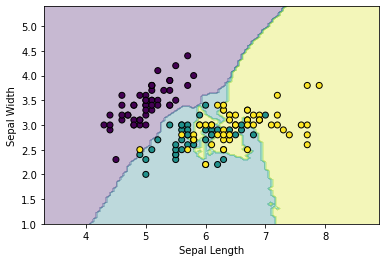

In [28]:
DecisionBoundaryDisplay.from_estimator(
    knn_plot,
    X_plot_train,
    response_method="predict",
    alpha=0.3,
    xlabel="Sepal Length",
    ylabel="Sepal Width"
)

plt.scatter(
    X_plot["sepal.length"],
    X_plot["sepal.width"],
    c=y_plot,
    edgecolor="black"
)

plt.show()

In [29]:
sepal_length = float(input("Enter sepal length: "))
sepal_width = float(input("Enter sepal width: "))
petal_length = float(input("Enter petal length: "))
petal_width = float(input("Enter petal width: "))

user_data = pd.DataFrame({
    "sepal.length": [sepal_length],
    "sepal.width": [sepal_width],
    "petal.length": [petal_length],
    "petal.width": [petal_width]
})

class_names = {
    0: "Setosa",
    1: "Versicolor",
    2: "Virginica"
}

print("\\nPredictions:")
print("K = 3:", class_names[knn3.predict(user_data)[0]])
print("K = 5:", class_names[knn5.predict(user_data)[0]])
print("K = 7:", class_names[knn7.predict(user_data)[0]])

Enter sepal length: 7
Enter sepal width: 2
Enter petal length: 6
Enter petal width: 2
\nPredictions:
K = 3: Virginica
K = 5: Virginica
K = 7: Virginica


In [30]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression()
log_reg.fit(X_train, y_train)

y_pred_test_lr = log_reg.predict(X_test)
y_pred_train_lr = log_reg.predict(X_train)

In [31]:
print("\nTest Statistics")
print(confusion_matrix(y_test, y_pred_test_lr))
print(accuracy_score(y_test, y_pred_test_lr))
print(precision_score(y_test, y_pred_test_lr, average='micro'))
print(recall_score(y_test, y_pred_test_lr, average='micro'))

print("\nTrain Statistics")
print(confusion_matrix(y_train, y_pred_train_lr))
print(accuracy_score(y_train, y_pred_train_lr))
print(precision_score(y_train, y_pred_train_lr, average='micro'))
print(recall_score(y_train, y_pred_train_lr, average='micro'))


Test Statistics
[[ 8  0  0]
 [ 0 13  0]
 [ 0  0  9]]
1.0
1.0
1.0

Train Statistics
[[42  0  0]
 [ 0 34  3]
 [ 0  0 41]]
0.975
0.975
0.975


In [32]:
lr_prediction = log_reg.predict(user_data)[0]
print(f"\nLogistic Prediction: {class_names[lr_prediction]}")


Logistic Prediction: Virginica


In [33]:
X_plot = df[["sepal.length", "sepal.width"]]
y_plot = df["variety"]

X_plot_train, X_plot_test, y_plot_train, y_plot_test = train_test_split(
    X_plot, y_plot, test_size=0.2, random_state=15
)

lg_plot = LogisticRegression().fit(X_plot_train, y_plot_train)

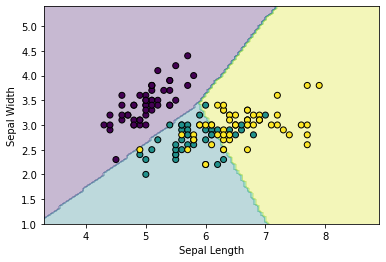

In [34]:
 DecisionBoundaryDisplay.from_estimator(
    lg_plot,
    X_plot_train,
    response_method="predict",
    alpha=0.3,
    xlabel="Sepal Length",
    ylabel="Sepal Width"
)

plt.scatter(
    X_plot["sepal.length"],
    X_plot["sepal.width"],
    c=y_plot,
    edgecolor="black"
)

plt.show()